# AeroGuard AI
## Assignment 1 Data Understanding and Exploratory Data Analysis
**Group 1 | NASA C-MAPSS**

This analysis characterizes the four C-MAPSS subsets and investigates FD001 sensor behavior, sensor–RUL correlations, engine lifetimes and feature selection. An engine-level development/validation partition separates exploratory decisions from held-out trajectories. The findings establish the data foundation for comparing Linear Regression, Random Forest, XGBoost and LSTM.

### 1. Sources and scope
- NASA dataset description: https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data
- Public dataset mirror used for reproducibility: https://github.com/DemetraAS/C-MAPSS
- Original reference: A. Saxena, K. Goebel, D. Simon and N. Eklund, “Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation,” PHM, 2008.

Each trajectory contains unit ID, operating cycle, three operational settings and 21 sensor values. Training engines run to failure; test histories end earlier. The RUL file provides the true remaining cycles at each test unit's final observation. These are simulated whole-engine trajectories, not individual component diagnoses.

In [1]:
from pathlib import Path  # Handle project directories and files.
from urllib.request import urlopen  # Download the public dataset files when they are absent.
import hashlib  # Verify file contents using SHA-256 checksums.
import json  # Save the engine split and dataset provenance.
import platform  # Record the Python version used to run the notebook.
import numpy as np  # Perform numerical calculations and create histogram bins.
import pandas as pd  # Load and summarize the tabular sensor data.
import matplotlib  # Record the plotting library version.
import matplotlib.pyplot as plt  # Create and save the EDA figures.
import sklearn  # Record the scikit-learn version.
from sklearn.model_selection import train_test_split  # Partition data by engine rather than by row.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()  # Support a root folder or a notebooks subfolder.
DATA_DIR = PROJECT_DIR / "data" / "raw"  # Locate the original input files.
FIGURE_DIR = PROJECT_DIR / "figures"  # Locate the exported figures.
RESULT_DIR = PROJECT_DIR / "results"  # Locate the exported tables and metadata.
for directory in [DATA_DIR, FIGURE_DIR, RESULT_DIR]:  # Prepare all output directories.
    directory.mkdir(parents=True, exist_ok=True)  # Create the directory without deleting existing files.
SEED = 42  # Reproduce the engine split used in the report.
RUL_CAP = 125  # Set a provisional cap rather than claim an optimal value.
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 160})  # Set consistent plot typography.
print({"Python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "matplotlib": matplotlib.__version__, "scikit-learn": sklearn.__version__})  # Record runtime versions.

{'Python': '3.12.14', 'numpy': '2.3.5', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'scikit-learn': '1.8.0'}


### 2. Dataset acquisition and integrity
SHA-256 checksums identify the original input files and detect changes in local or downloaded data. The provenance record contains each file’s source URL, byte size and checksum.

In [2]:
EXPECTED_SHA256 = {  # Define the input file checksums.
    'RUL_FD001.txt': 'a19c8ec94931949d0485bdc35118206e9c81c4547b422efb9cf86f4ceddbceca',  # Verify RUL_FD001.txt.
    'RUL_FD002.txt': 'c851dd96a6ea6998d3c4a8f834d3c8013aa90e93a6ed950dc826ad0655b2906b',  # Verify RUL_FD002.txt.
    'RUL_FD003.txt': 'df1e0566306b174a2de41c67a3e7a51877889598b78643fc3e5685259091b7cb',  # Verify RUL_FD003.txt.
    'RUL_FD004.txt': '196b836b85a95ac7fdbbf29c5fdf1657382eafa445644d114ffaaf50dc2975e1',  # Verify RUL_FD004.txt.
    'test_FD001.txt': '3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf95eb55d1ddd6f52851',  # Verify test_FD001.txt.
    'test_FD002.txt': 'de7b5bf7e998a985c378488480528b7c02cff1406a46740def362dda8d9b4e02',  # Verify test_FD002.txt.
    'test_FD003.txt': '299babd63c8d987cef079c4a425429f33b3a34797d803bbe2ad48c29dbd0d790',  # Verify test_FD003.txt.
    'test_FD004.txt': '1dc675fff0624bac10786927c6715b37d1297657137400d2b1a3138d777a3ba5',  # Verify test_FD004.txt.
    'train_FD001.txt': '963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8834ba4b5d91d2de0f8',  # Verify train_FD001.txt.
    'train_FD002.txt': 'dac6c4dbc4e7c1bdeb5747da3d313d05c395bb99801b44a002b26a2ba13d788f',  # Verify train_FD002.txt.
    'train_FD003.txt': '2abbe9968cc5e8eb091980f51b20f62bb4127336d3482cb52071d53bf23329e2',  # Verify train_FD003.txt.
    'train_FD004.txt': '27ef6160b6a1dcb2613a88de9c239f763b223f02cdc41dc5cdedc5dc189b6218',  # Verify train_FD004.txt.
}  # Finish the checksum mapping.

In [3]:
BASE_URL = "https://raw.githubusercontent.com/DemetraAS/C-MAPSS/main/"  # Use a public mirror of the NASA files.
provenance = []  # Collect one provenance record per input file.
for filename, expected_hash in EXPECTED_SHA256.items():  # Retrieve all train, test and RUL files for the four subsets.
    path = DATA_DIR / filename  # Resolve the local input path.
    if not path.exists():  # Reuse previously verified files on later runs.
        try:  # Report network failures with an actionable message.
            with urlopen(BASE_URL + filename, timeout=120) as response:  # Open the original TXT file.
                content = response.read()  # Read the complete response before saving it.
        except Exception as error:  # Handle blocked or unavailable downloads.
            raise RuntimeError(f"Download failed for {filename}; input unavailable in {DATA_DIR}.") from error  # Explain the offline fallback.
        downloaded_hash = hashlib.sha256(content).hexdigest()  # Check bytes before writing a new file.
        if downloaded_hash != expected_hash:  # Detect source changes or incomplete content.
            raise ValueError(f"Unexpected checksum for downloaded {filename}.")  # Stop instead of using unverified data.
        path.write_bytes(content)  # Save the verified original TXT file.
    actual_hash = hashlib.sha256(path.read_bytes()).hexdigest()  # Verify cached files as well.
    if actual_hash != expected_hash:  # Detect local changes to the original data.
        raise ValueError(f"Checksum mismatch for {path}; restore the original file.")  # Stop on a changed input.
    provenance.append({"file": filename, "sha256": actual_hash, "bytes": path.stat().st_size, "source_url": BASE_URL + filename})  # Record provenance.
print(f"Verified {len(provenance)} dataset files.")  # Confirm that all four subsets are available.
(RESULT_DIR / "data_provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")  # Save the input manifest.

Verified 12 dataset files.


### 3. Dataset structure
Engine counts are computed directly from the original files. Operating-condition and fault-mode counts follow the NASA dataset specification. The files contain 249 training and 248 test engines for FD004; the catalog prose reverses those two counts. Fault modes characterize the subset; they are not explicit label columns in the raw history files.

In [4]:
SENSOR_COLS = [f"s{i}" for i in range(1, 22)]  # Name the 21 sensor columns in their original order.
COLUMNS = ["unit", "cycle", "op1", "op2", "op3"] + SENSOR_COLS  # Name all 26 input columns.
def read_history(filename):  # Load one multivariate engine history file.
    frame = pd.read_csv(DATA_DIR / filename, sep=r"\s+", header=None)  # Parse variable amounts of whitespace.
    if frame.shape[1] != 26:  # Validate the raw schema before assigning names.
        raise ValueError(f"Expected 26 columns in {filename}, found {frame.shape[1]}.")  # Reject an incompatible dataset.
    frame.columns = COLUMNS  # Apply readable variable names.
    frame[["unit", "cycle"]] = frame[["unit", "cycle"]].astype(int)  # Store identifiers and cycle counts as integers.
    return frame  # Return the loaded history without changing the raw file.
train_sets = {}  # Store the four run-to-failure training tables.
subset_records = []  # Store the dataset comparison table.
for subset, conditions, faults in [("FD001", 1, 1), ("FD002", 6, 1), ("FD003", 1, 2), ("FD004", 6, 2)]:  # Define NASA subset metadata.
    training = read_history(f"train_{subset}.txt")  # Load this subset's complete training trajectories.
    testing = read_history(f"test_{subset}.txt")  # Inspect test metadata without using its labels for decisions.
    train_sets[subset] = training  # Retain the training table for later FD001 analysis.
    subset_records.append({"Subset": subset, "Train engines": training.unit.nunique(), "Test engines": testing.unit.nunique(), "Operating conditions": conditions, "Fault modes": faults, "Train rows": len(training), "Test rows": len(testing)})  # Summarize observed counts.
subset_summary = pd.DataFrame(subset_records)  # Build a readable comparison table.
print(subset_summary.to_string(index=False))  # Display all four subsets.
subset_summary.to_csv(RESULT_DIR / "subset_summary.csv", index=False)  # Export the comparison table.

Subset  Train engines  Test engines  Operating conditions  Fault modes  Train rows  Test rows
 FD001            100           100                     1            1       20631      13096
 FD002            260           259                     6            1       53759      33991
 FD003            100           100                     1            2       24720      16596
 FD004            249           248                     6            2       61249      41214


**Dataset overview.** FD001 contains one operating condition and one fault mode and is selected for the initial analysis. FD002 and FD004 contain six operating conditions; FD003 and FD004 contain two fault modes. These differences motivate separate assessments of sensor behavior and normalization across subsets.

In [5]:
train = train_sets["FD001"].copy()  # Select the initial subset without modifying the stored data.
quality = pd.DataFrame([{"Rows": len(train), "Columns": train.shape[1], "Engines": train.unit.nunique(), "Missing values": int(train.isna().sum().sum()), "Duplicate rows": int(train.duplicated().sum()), "Duplicate unit-cycle keys": int(train.duplicated(["unit", "cycle"]).sum())}])  # Inspect input quality.
print(quality.to_string(index=False))  # Display the quality audit.
assert train.shape == (20631, 26)  # Verify the FD001 schema and observation count.
assert not train.isna().any().any()  # Require complete numeric input data.
assert not train.duplicated(["unit", "cycle"]).any()  # Require one observation per engine cycle.
assert (train.groupby("unit").cycle.min() == 1).all()  # Confirm that training trajectories start at cycle one.
assert train.groupby("unit").cycle.apply(lambda values: np.array_equal(values.to_numpy(), np.arange(1, len(values) + 1))).all()  # Confirm ordered and consecutive cycles.
quality.to_csv(RESULT_DIR / "fd001_quality.csv", index=False)  # Export the audit.
print(train.head().to_string(index=False))  # Preview the schema and a few input observations.

 Rows  Columns  Engines  Missing values  Duplicate rows  Duplicate unit-cycle keys
20631       26      100               0               0                          0
 unit  cycle     op1     op2   op3     s1     s2      s3      s4    s5    s6     s7      s8      s9  s10   s11    s12     s13     s14    s15  s16  s17  s18   s19   s20     s21
    1      1 -0.0007 -0.0004 100.0 518.67 641.82 1589.70 1400.60 14.62 21.61 554.36 2388.06 9046.19  1.3 47.47 521.66 2388.02 8138.62 8.4195 0.03  392 2388 100.0 39.06 23.4190
    1      2  0.0019 -0.0003 100.0 518.67 642.15 1591.82 1403.14 14.62 21.61 553.75 2388.04 9044.07  1.3 47.49 522.28 2388.07 8131.49 8.4318 0.03  392 2388 100.0 39.00 23.4236
    1      3 -0.0043  0.0003 100.0 518.67 642.35 1587.99 1404.20 14.62 21.61 554.26 2388.08 9052.94  1.3 47.27 522.42 2388.03 8133.23 8.4178 0.03  390 2388 100.0 38.95 23.3442
    1      4  0.0007  0.0000 100.0 518.67 642.35 1582.79 1401.87 14.62 21.61 554.45 2388.11 9049.48  1.3 47.13 522.86 2388.08 8133

### 4. Engine-level development and validation partition
The 100 FD001 training engines are divided into 80 development units and 20 held-out validation units using seed 42. All rows and windows from an engine remain in the same partition. Sensor decisions use development data only. Aggregate lifetime statistics across the full training fleet provide descriptive context; official test labels are excluded from feature decisions.

In [6]:
engine_ids = sorted(train.unit.unique())  # Sort unit IDs before applying the reproducible split.
development_ids, validation_ids = train_test_split(engine_ids, test_size=0.20, random_state=SEED)  # Hold out complete engines.
development = train.loc[train.unit.isin(development_ids)].copy()  # Keep all observations from development engines.
validation = train.loc[train.unit.isin(validation_ids)].copy()  # Reserve all observations from validation engines.
assert set(development.unit).isdisjoint(set(validation.unit))  # Verify that no engine appears in both partitions.
assert len(development) == 16561  # Validate the development partition size.
for partition in [development, validation]:  # Construct labels independently within each partition.
    final_cycles = partition.groupby("unit").cycle.transform("max")  # Identify the failure cycle of each training trajectory.
    partition["RUL"] = final_cycles - partition.cycle  # Compute uncapped remaining cycles to failure.
    partition["RUL_capped"] = partition.RUL.clip(upper=RUL_CAP)  # Create the provisional piecewise target.
split_record = {"seed": SEED, "development_units": sorted(map(int, development_ids)), "validation_units": sorted(map(int, validation_ids))}  # Record the exact partition.
(RESULT_DIR / "engine_split.json").write_text(json.dumps(split_record, indent=2), encoding="utf-8")  # Save a reusable split manifest.
print(f"Development: {len(development_ids)} engines, {len(development):,} rows")  # Summarize the development partition.
print(f"Validation: {len(validation_ids)} engines, {len(validation):,} rows")  # Summarize the held-out partition.
print("Validation units:", split_record["validation_units"])  # List the held-out validation engine IDs.

Development: 80 engines, 16,561 rows
Validation: 20 engines, 4,070 rows
Validation units: [1, 5, 11, 13, 19, 23, 31, 32, 34, 40, 45, 46, 54, 71, 74, 77, 78, 81, 84, 91]


### 5. Audit sensors on development engines
Exactly constant sensors are detected by the number of unique values. Sensor s6 is treated separately: it is nearly constant, not exactly constant. This distinction avoids removing sensors solely because their raw variance is small in their measurement units.

In [7]:
unique_counts = development[SENSOR_COLS].nunique()  # Count distinct development readings for each sensor.
constant_sensors = unique_counts[unique_counts == 1].index.tolist()  # Detect sensors with exactly one observed value.
assert constant_sensors == ["s1", "s5", "s10", "s16", "s18", "s19"]  # Validate the constant-sensor classification.
s6_counts = development["s6"].value_counts().sort_index()  # Inspect the two nearly constant s6 values.
s6_range = development.s6.max() - development.s6.min()  # Quantify the narrow s6 range.
s6_correlation = development.s6.corr(development.RUL)  # Check the weak linear relationship with uncapped RUL.
assert unique_counts["s6"] == 2 and np.isclose(s6_range, 0.01)  # Validate the evidence supporting the separate s6 decision.
excluded_sensors = [sensor for sensor in SENSOR_COLS if sensor in constant_sensors or sensor == "s6"]  # Apply the initial FD001 selection.
retained_sensors = [sensor for sensor in SENSOR_COLS if sensor not in excluded_sensors]  # Retain 14 varying sensors.
print("Exactly constant:", constant_sensors)  # List the six exactly constant channels.
print("s6 value counts:", s6_counts.to_dict())  # Display the nearly constant readings.
print(f"s6 range = {s6_range:.2f}; correlation with RUL = {s6_correlation:.3f}")  # Quantify the near-constant channel.
print("Retained sensors:", retained_sensors)  # Record the initial model input channels.

Exactly constant: ['s1', 's5', 's10', 's16', 's18', 's19']
s6 value counts: {21.6: 314, 21.61: 16247}
s6 range = 0.01; correlation with RUL = -0.117
Retained sensors: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


### 6. Sensor readings over operating cycles

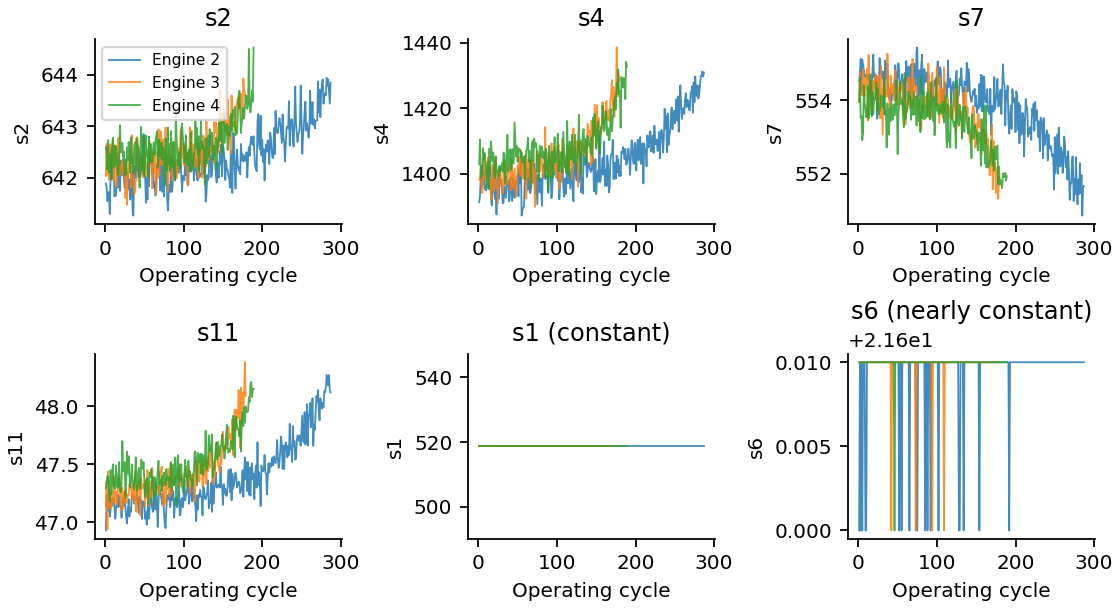

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(7, 3.8), constrained_layout=True)  # Create a six-panel sensor comparison.
for ax, sensor in zip(axes.flat, ["s2", "s4", "s7", "s11", "s1", "s6"]):  # Compare degrading and constant channels.
    for unit in [2, 3, 4]:  # Plot three development engines only.
        engine = development.loc[development.unit == unit]  # Isolate the complete engine trajectory.
        ax.plot(engine.cycle, engine[sensor], linewidth=0.8, alpha=0.85, label=f"Engine {unit}")  # Preserve raw sensor noise.
    suffix = " (constant)" if sensor == "s1" else " (nearly constant)" if sensor == "s6" else ""  # Distinguish the flat channels.
    ax.set(xlabel="Operating cycle", ylabel=sensor, title=sensor + suffix)  # Label each panel.
axes[0, 0].legend(fontsize=7)  # Identify the three selected engines.
fig.savefig(FIGURE_DIR / "figure_3_1_sensor_histories.png", dpi=160)  # Export Figure 3.1.
plt.show()  # Display the complete figure in the notebook.
plt.close(fig)  # Release the figure after display.

**Figure 3.1. Sensor behavior.** In development engines 2, 3 and 4, s2, s4 and s11 generally increase toward failure, while s7 generally decreases. Noise and different starting levels limit the usefulness of a single universal threshold. Sensor s1 is exactly constant, whereas s6 switches between two closely spaced values.

### 7. Sensor correlations and relationship with RUL
The Pearson matrix uses uncapped development RUL. Constant channels are omitted because their correlations are undefined; s6 is excluded under the near-constant sensor decision.

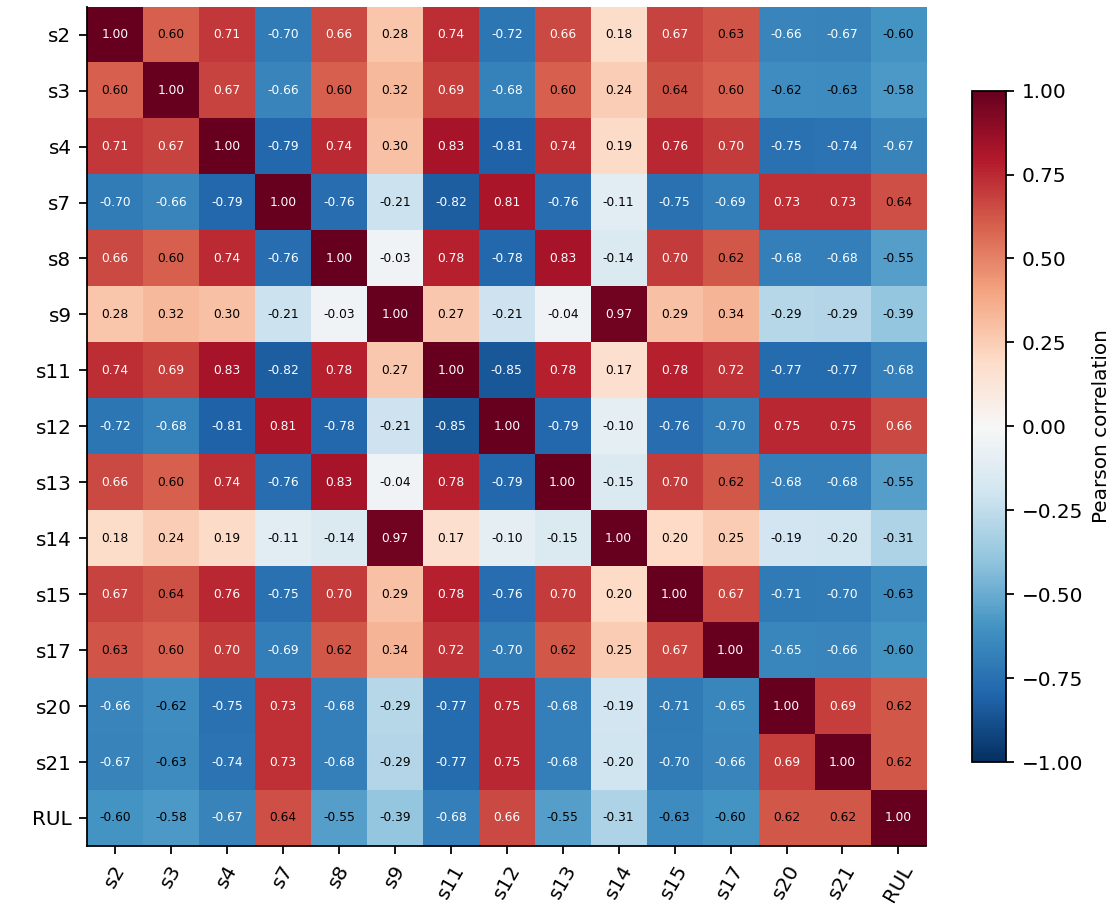

s11   -0.684
s4    -0.666
s15   -0.631
s2    -0.597
s17   -0.596
s3    -0.575
s8    -0.551
s13   -0.548
s9    -0.387
s14   -0.308
s20    0.619
s21    0.624
s7     0.645
s12    0.658
s9–s14: 0.965; s8–s13: 0.826


In [9]:
correlation = development[retained_sensors + ["RUL"]].corr(method="pearson")  # Compute pooled development correlations.
fig, ax = plt.subplots(figsize=(7, 5.7), constrained_layout=True)  # Allocate readable space for all matrix entries.
heatmap = ax.imshow(correlation, vmin=-1, vmax=1, cmap="RdBu_r")  # Use a symmetric scale for correlation signs.
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=60)  # Label input sensors and RUL on the x-axis.
ax.set_yticks(range(len(correlation)), correlation.index)  # Label input sensors and RUL on the y-axis.
for row in range(len(correlation)):  # Visit each matrix row.
    for column in range(len(correlation)):  # Visit each matrix column.
        value = correlation.iloc[row, column]  # Read the correlation coefficient.
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", fontsize=5.5, color="white" if abs(value) > 0.65 else "black")  # Annotate the matrix.
fig.colorbar(heatmap, ax=ax, shrink=0.8, label="Pearson correlation")  # Explain the color scale.
fig.savefig(FIGURE_DIR / "figure_3_2_correlation_matrix.png", dpi=160)  # Export Figure 3.2.
plt.show()  # Display the correlation matrix.
plt.close(fig)  # Release the figure after display.
correlation.to_csv(RESULT_DIR / "development_correlations.csv")  # Export the numerical matrix.
rul_correlations = correlation.loc[retained_sensors, "RUL"].rename("Correlation with uncapped RUL")  # Extract the target relationship.
print(rul_correlations.sort_values().round(3).to_string())  # Display sensor-to-target correlations.
print(f"s9–s14: {correlation.loc['s9', 's14']:.3f}; s8–s13: {correlation.loc['s8', 's13']:.3f}")  # Show the highly correlated pairs.

**Figure 3.2. Correlation analysis.** Negative sensor–RUL relationships include s11 (−0.684), s4 (−0.666) and s15 (−0.631). Positive relationships include s12 (+0.658), s7 (+0.645) and s21 (+0.624). The s9–s14 (+0.965) and s8–s13 (+0.826) pairs indicate substantial redundancy. Their initial retention will be assessed through validation-based ablation. These pooled observations are temporally dependent; the correlations describe associations rather than causal failure mechanisms.

### 8. Engine lifetime distribution and provisional RUL cap

       All training engines  Development engines
count                100.00                80.00
mean                 206.31               207.01
std                   46.34                47.46
min                  128.00               128.00
25%                  177.00               179.75
50%                  199.00               199.00
75%                  229.25               216.25
max                  362.00               362.00


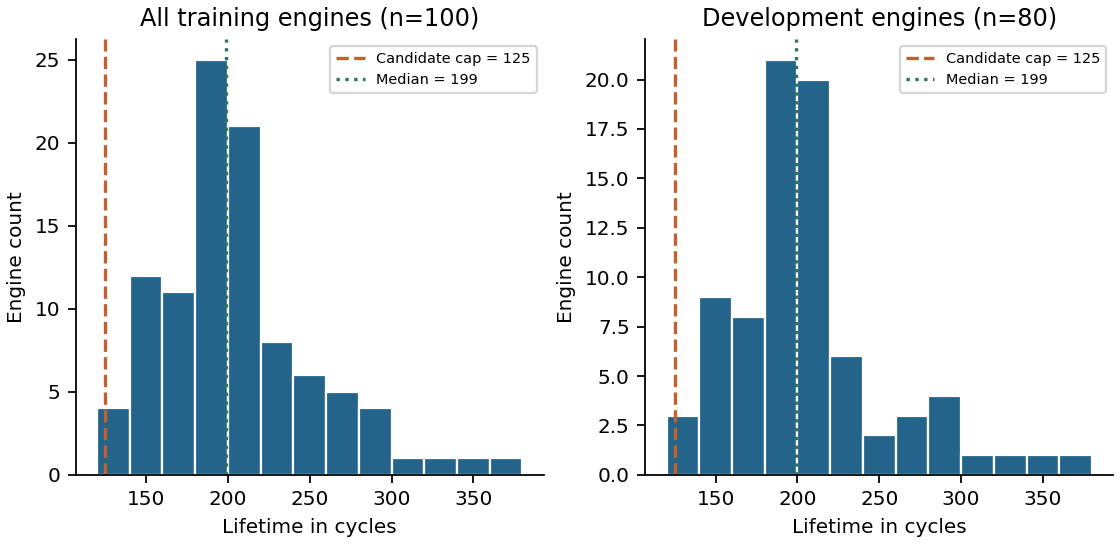

 Candidate cap  Development rows above cap (%)  Below minimum development lifetime
           100                           51.21                                True
           125                           39.13                                True
           150                           27.42                               False


In [10]:
all_lifetimes = train.groupby("unit").cycle.max()  # Obtain failure cycles for all 100 training engines.
development_lifetimes = development.groupby("unit").cycle.max()  # Obtain failure cycles for the 80 development engines.
lifetime_summary = pd.DataFrame({"All training engines": all_lifetimes.describe(), "Development engines": development_lifetimes.describe()})  # Summarize lifetime variation.
print(lifetime_summary.round(2).to_string())  # Display descriptive lifetime statistics.
lifetime_summary.to_csv(RESULT_DIR / "lifetime_summary.csv")  # Export the lifetime statistics.
fig, axes = plt.subplots(1, 2, figsize=(7, 3.4), constrained_layout=True)  # Compare descriptive and decision-making partitions.
for ax, lifetimes, title in zip(axes, [all_lifetimes, development_lifetimes], ["All training engines (n=100)", "Development engines (n=80)"]):  # Plot both lifetime distributions.
    ax.hist(lifetimes, bins=np.arange(120, 381, 20), color="#24648a", edgecolor="white")  # Use equal-width 20-cycle bins.
    ax.axvline(RUL_CAP, color="#c2602f", linestyle="--", label=f"Candidate cap = {RUL_CAP}")  # Show the provisional cap.
    ax.axvline(lifetimes.median(), color="#2f7459", linestyle=":", label=f"Median = {lifetimes.median():.0f}")  # Show the median lifetime.
    ax.set(title=title, xlabel="Lifetime in cycles", ylabel="Engine count")  # Label the histogram.
    ax.legend(fontsize=6.5)  # Distinguish the reference lines.
fig.savefig(FIGURE_DIR / "figure_3_3_lifetime_distribution.png", dpi=160)  # Export Figure 3.3.
plt.show()  # Display both lifetime distributions.
plt.close(fig)  # Release the figure after display.
cap_analysis = pd.DataFrame([{"Candidate cap": cap, "Development rows above cap (%)": 100 * (development.RUL > cap).mean(), "Below minimum development lifetime": bool(cap < development_lifetimes.min())} for cap in [100, 125, 150]])  # Quantify candidate caps without fitting a model.
print(cap_analysis.round(2).to_string(index=False))  # Display the fraction affected by each cap.
cap_analysis.to_csv(RESULT_DIR / "candidate_cap_analysis.csv", index=False)  # Export the candidate-cap audit.

**Figure 3.3. Lifetime distribution and cap selection.** Training lifetimes range from 128 to 362 cycles, with mean 206.31 and median 199. The development mean is 207.01 and its median is 199. A 125-cycle cap lies below every development lifetime and caps 39.13% of development rows. It is an initial target-design choice, not an estimate of the exact degradation onset. Caps of 100, 125 and 150 will be compared using held-out validation engines before final test evaluation.

### 9. Sensor selection
The decision table covers all 21 sensor channels and documents their inclusion or exclusion using development-set evidence. The resulting 14-channel feature set applies to the initial FD001 analysis; more complex subsets require separate assessment.

In [11]:
selection_records = []  # Collect one explanation for every sensor.
for sensor in SENSOR_COLS:  # Include all 21 channels, including excluded channels.
    if sensor in constant_sensors:  # Explain exact constant-channel exclusion.
        decision, reason, evidence = "Exclude", "Exactly constant; 1 unique value and range 0", "Development audit; Figure 3.1 illustrates s1"  # Record the observed evidence.
    elif sensor == "s6":  # Explain the separate near-constant exclusion.
        decision, reason, evidence = "Exclude", f"Near constant; 2 unique values, range {s6_range:.2f}; r(RUL) = {s6_correlation:.3f}", "Development audit and Figure 3.1"  # Preserve the distinction from exact constancy.
    else:  # Retain the other varying sensor channels initially.
        decision, reason, evidence = "Keep", f"{unique_counts[sensor]:,} unique values; r(RUL) = {rul_correlations[sensor]:+.3f}", "Figure 3.2"  # Quantify variation and the target relationship.
    selection_records.append({"Sensor": sensor, "Decision": decision, "Reason": reason, "Evidence": evidence})  # Add the complete decision row.
sensor_selection = pd.DataFrame(selection_records)  # Build the complete sensor-selection table.
print(sensor_selection.to_string(index=False))  # Display all inclusion and exclusion reasons.
sensor_selection.to_csv(RESULT_DIR / "sensor_selection.csv", index=False)  # Export the complete decision table.
assert len(retained_sensors) == 14 and len(excluded_sensors) == 7  # Verify the expected initial feature counts.

Sensor Decision                                                      Reason                                     Evidence
    s1  Exclude                Exactly constant; 1 unique value and range 0 Development audit; Figure 3.1 illustrates s1
    s2     Keep                          305 unique values; r(RUL) = -0.597                                   Figure 3.2
    s3     Keep                        2,878 unique values; r(RUL) = -0.575                                   Figure 3.2
    s4     Keep                        3,893 unique values; r(RUL) = -0.666                                   Figure 3.2
    s5  Exclude                Exactly constant; 1 unique value and range 0 Development audit; Figure 3.1 illustrates s1
    s6  Exclude Near constant; 2 unique values, range 0.01; r(RUL) = -0.117             Development audit and Figure 3.1
    s7     Keep                          501 unique values; r(RUL) = +0.645                                   Figure 3.2
    s8     Keep                 

### 10. Modeling and evaluation framework
The modeling phase will use Min–Max normalization fitted on development engines and trailing 30-cycle windows constructed within individual trajectories. A common history and target definition will support comparison of Linear Regression, Random Forest, XGBoost and LSTM. Short trajectories will follow the same left-padding convention for all models, with a separate sensitivity assessment.

Model tuning will use held-out validation engines with reproducibly truncated histories. Official test evaluation will use the final observed endpoint of each engine. Raw-label and capped-target metrics will be identified separately, with consistent engine coverage when comparing published results. Stochastic models will be evaluated across repeated seeds.

For error $d_i=\hat y_i-y_i$, $\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i d_i^2}$. The NASA score is $\sum_i s(d_i)$, where $s(d_i)=e^{-d_i/13}-1$ for $d_i<0$, and $s(d_i)=e^{d_i/10}-1$ otherwise. Optimistic overestimation receives a larger penalty than equally sized early prediction.

The display indicator is $H=\min(100,\max(0,100\hat y/C))$. Healthy corresponds to $H>60$, Warning to $30\leq H\leq60$, and Critical to $H<30$. This indicator rescales predicted remaining cycles; it is not a calibrated probability of failure.

In [12]:
def evaluate_rul(y_true, y_pred):  # Define the endpoint evaluation metrics.
    truth, prediction = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)  # Convert numeric inputs to arrays.
    if truth.ndim != 1 or truth.shape != prediction.shape or truth.size == 0:  # Require matching nonempty vectors.
        raise ValueError("Use matching nonempty one-dimensional endpoint arrays.")  # Reject incompatible inputs.
    if not np.isfinite(truth).all() or not np.isfinite(prediction).all():  # Check for invalid metric inputs.
        raise ValueError("Metric inputs must contain finite values.")  # Prevent misleading scores from missing values.
    errors = prediction - truth  # Use positive errors for optimistic overestimation.
    penalties = np.empty_like(errors)  # Allocate one asymmetric penalty per endpoint.
    negative = errors < 0  # Separate early predictions from optimistic predictions.
    penalties[negative] = np.expm1(-errors[negative] / 13.0)  # Penalize early predictions with divisor 13.
    penalties[~negative] = np.expm1(errors[~negative] / 10.0)  # Penalize optimistic predictions with divisor 10.
    return {"RMSE": float(np.sqrt(np.mean(errors ** 2))), "NASA score": float(penalties.sum())}  # Return cycle error and the summed asymmetric score.
def health_display(predicted_rul, cap=RUL_CAP):  # Define the project's later dashboard display rule.
    if cap <= 0 or not np.isfinite(cap) or not np.isfinite(predicted_rul):  # Require a valid positive cap and finite prediction.
        raise ValueError("Use a finite RUL and a finite positive cap.")  # Reject an undefined display calculation.
    score = float(np.clip(100.0 * predicted_rul / cap, 0.0, 100.0))  # Bound the RUL-derived indicator between zero and 100.
    status = "Healthy" if score > 60 else "Warning" if score >= 30 else "Critical"  # Apply the stated inclusive status boundaries.
    return {"Health score (%)": score, "Status": status}  # Return a display indicator rather than failure probability.
assert evaluate_rul([10.0], [10.0]) == {"RMSE": 0.0, "NASA score": 0.0}  # Confirm the zero-error definition.
assert evaluate_rul([20.0], [30.0])["NASA score"] > evaluate_rul([20.0], [10.0])["NASA score"]  # Verify a larger penalty for equally optimistic error.
assert health_display(40.0) == {"Health score (%)": 32.0, "Status": "Warning"}  # Verify the health indicator calculation.
print("Evaluation and health indicator definitions verified.")  # Distinguish formula checks from model results.

Evaluation and health indicator definitions verified.


### 11. Analysis summary
The final summary records the partition sizes, selected sensors and provisional cap. These outputs support reproducibility of the exploratory analysis.

In [13]:
summary = {"fd001_rows": len(train), "development_rows": len(development), "validation_rows": len(validation), "retained_sensors": retained_sensors, "excluded_sensors": excluded_sensors, "provisional_rul_cap": RUL_CAP, "development_rows_capped_percent": 100 * (development.RUL > RUL_CAP).mean(), "model_training_performed": False}  # Summarize the exploratory analysis.
(RESULT_DIR / "eda_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")  # Save the analysis summary.
print(json.dumps(summary, indent=2))  # Display the executed analysis summary.
print("Figure files:", [path.name for path in sorted(FIGURE_DIR.glob("figure_3_*.png"))])  # List the three exported EDA figures.

{
  "fd001_rows": 20631,
  "development_rows": 16561,
  "validation_rows": 4070,
  "retained_sensors": [
    "s2",
    "s3",
    "s4",
    "s7",
    "s8",
    "s9",
    "s11",
    "s12",
    "s13",
    "s14",
    "s15",
    "s17",
    "s20",
    "s21"
  ],
  "excluded_sensors": [
    "s1",
    "s5",
    "s6",
    "s10",
    "s16",
    "s18",
    "s19"
  ],
  "provisional_rul_cap": 125,
  "development_rows_capped_percent": 39.13411025904232,
  "model_training_performed": false
}
Figure files: ['figure_3_1_sensor_histories.png', 'figure_3_2_correlation_matrix.png', 'figure_3_3_lifetime_distribution.png']


### Conclusions
FD001 contains 100 training engines and 20,631 observations, with no missing values or duplicate unit-cycle keys in the audit. Six exactly constant channels and the nearly constant s6 are excluded, leaving 14 initial features. Sensor trends and correlations show informative degradation patterns alongside noise and redundancy. Lifetime variation supports further comparison of target caps during validation. These findings establish the inputs and evaluation protocol for the subsequent modeling phase.